# 08 - Eficiência Computacional e Tabela-Resumo Final

| Métrica | Sistema Especialista | Árvore / Ensembles |
|---|---|---|
| Tempo de elaboração das regras (cronômetro) | Sim (notebook 03) | Não se aplica |
| Tempo de treinamento (wall-clock) | Não se aplica | Sim (5 repetições) |
| Tempo de inferência (total e por amostra) e vazão | Sim (30 repetições) | Sim (30 repetições) |
| Pico de memória (tracemalloc) | Só inferência | Treino e inferência |
| Tamanho em disco | Arquivo de regras | Modelo serializado (joblib) |
| Complexidade | Nº de regras | Profundidade, nós, árvores |
| Energia (kWh) e CO₂ | Só inferência | Treino e inferência |

- Tempo com `time.perf_counter`; memória com `tracemalloc` (medida em execução separada
  para não inflar o tempo).
- Limitação: o `tracemalloc` só enxerga alocações feitas via Python/NumPy (cópias dos
  dados, vetores de previsão). As estruturas internas das árvores são alocadas em C pelo
  scikit-learn e não aparecem, por isso o pico de treino fica parecido entre os modelos.
  O **tamanho serializado em disco** é o melhor indicador do tamanho do modelo em memória.
- Todos os modelos rodam com **1 núcleo** (`n_jobs=1`) nas medições, para comparação justa.
- **Energia:** estimativa `E = P × t`, com P = TDP do processador (65 W, Ryzen 5 5600X),
  um limite superior. **CO₂** = E × 45,8 gCO₂/kWh (fator de emissão do Brasil apresentado
  em aula). A biblioteca codecarbon não foi usada: no Windows, sem RAPL/Intel Power
  Gadget para AMD, ela também recorre a uma estimativa por TDP.

In [1]:
import sys
sys.path.insert(0, "..")
import warnings
warnings.filterwarnings("ignore")

import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
import sklearn

from src.config import (FATOR_EMISSAO_BR, POTENCIA_CPU_W, TABLES, carregar_split, salvar_fig,
                        salvar_tabela)
from src.models import SistemaEspecialista, carregar_modelos
from src.profiling import complexidade, energia_co2, medir_inferencia, medir_treino, tamanho_disco_kb

sns.set_style("whitegrid")

## 1. Ambiente computacional

In [2]:
ambiente = pd.Series({
    "Sistema operacional": f"{platform.system()} {platform.release()} ({platform.version()})",
    "Processador": "AMD Ryzen 5 5600X 6-Core (12 threads, 3.7 GHz, TDP 65 W)",
    "Núcleos físicos / lógicos": f"{psutil.cpu_count(logical=False)} / {psutil.cpu_count()}",
    "Memória RAM (GB)": round(psutil.virtual_memory().total / 1024**3, 1),
    "Python": platform.python_version(),
    "scikit-learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
}, name="valor")
salvar_tabela(ambiente.to_frame(), "ambiente")
ambiente.to_frame()

,valor
Sistema operacional,Windows 10 (10.0.19045)
Processador,"AMD Ryzen 5 5600X 6-Core (12 threads, 3.7 GHz,..."
Núcleos físicos / lógicos,6 / 12
Memória RAM (GB),15.9
Python,3.13.3
scikit-learn,1.7.2
pandas,3.0.5
numpy,2.5.3


## 2. Medições

In [3]:
def medir(problema):
    X_train, X_test, y_train, _ = carregar_split(problema)
    linhas = []
    for nome, m in carregar_modelos(problema).items():
        print(f"medindo {problema} - {nome}...", flush=True)
        linha = {"modelo": nome}
        if isinstance(m, SistemaEspecialista):
            linha.update({"treino_tempo_medio_s": np.nan, "treino_tempo_desvio_s": np.nan,
                          "treino_pico_memoria_kb": np.nan,
                          "disco_kb": tamanho_disco_kb(arquivo=m.arquivo),
                          "n_regras": len(m.motor.base)})
        else:
            if "n_jobs" in m.get_params():
                m.set_params(n_jobs=1)
            treino, m = medir_treino(m, X_train, y_train, n_rep=5)
            linha.update(treino)
            linha.update({"disco_kb": tamanho_disco_kb(m), **complexidade(m)})
        linha.update(medir_inferencia(m.predict, X_test, n_rep=30))
        e_tr, c_tr = energia_co2(linha["treino_tempo_medio_s"])
        e_inf, c_inf = energia_co2(linha["inf_tempo_medio_s"])
        linha.update({"treino_energia_kwh": e_tr, "treino_co2_g": c_tr,
                      "inf_energia_kwh": e_inf, "inf_co2_g": c_inf})
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index("modelo")


efic = {p: medir(p) for p in ("classificacao", "regressao")}
for p, df in efic.items():
    salvar_tabela(df, f"eficiencia_{p}")

medindo classificacao - Sistema Especialista...


medindo classificacao - Árvore (sem restrição)...


medindo classificacao - Árvore (ajustada)...


medindo classificacao - Random Forest...


medindo classificacao - Gradient Boosting...


medindo regressao - Sistema Especialista...


medindo regressao - Árvore (sem restrição)...


medindo regressao - Árvore (ajustada)...


medindo regressao - Random Forest...


medindo regressao - Gradient Boosting...


In [4]:
efic["classificacao"].T

modelo,Sistema Especialista,Árvore (sem restrição),Árvore (ajustada),Random Forest,Gradient Boosting
treino_tempo_medio_s,NaN,8.002164e-02,5.823118e-02,2.650390e+00,5.285466e+00
treino_tempo_desvio_s,NaN,1.326635e-04,3.973915e-04,2.968044e-02,5.794696e-02
treino_pico_memoria_kb,NaN,2.540864e+03,2.540739e+03,2.537997e+03,2.537462e+03
disco_kb,1.941406e+00,1.014932e+02,2.914941e+01,1.849445e+04,3.877598e+02
n_regras,1.400000e+01,NaN,NaN,NaN,NaN
inf_tempo_medio_s,2.984143e-02,8.283200e-04,8.089967e-04,4.973542e-02,6.702513e-03
inf_tempo_desvio_s,2.717793e-03,8.864936e-05,1.017913e-04,4.992252e-03,1.350540e-04
inf_tempo_por_amostra_ms,1.657857e-02,4.601778e-04,4.494426e-04,2.763079e-02,3.723619e-03
inf_vazao_amostras_s,6.031883e+04,2.173073e+06,2.224978e+06,3.619151e+04,2.685560e+05
inf_pico_memoria_kb,1.857042e+03,6.356357e+02,6.356357e+02,6.356436e+02,6.355303e+02


In [5]:
efic["regressao"].T

modelo,Sistema Especialista,Árvore (sem restrição),Árvore (ajustada),Random Forest,Gradient Boosting
treino_tempo_medio_s,NaN,1.252563e-01,3.018986e-02,4.789753e+00,2.775672e+00
treino_tempo_desvio_s,NaN,5.441187e-03,4.170884e-04,6.352825e-02,9.590662e-03
treino_pico_memoria_kb,NaN,2.540818e+03,2.540693e+03,2.538021e+03,2.537471e+03
disco_kb,1.622070e+00,8.862197e+02,6.047852e+00,7.193267e+03,2.302598e+02
n_regras,9.000000e+00,NaN,NaN,NaN,NaN
inf_tempo_medio_s,2.389655e-02,1.013627e-03,8.326000e-04,3.789310e-02,4.270027e-03
inf_tempo_desvio_s,2.223120e-03,1.314921e-04,1.446791e-04,4.379890e-04,1.151032e-04
inf_tempo_por_amostra_ms,1.327586e-02,5.631259e-04,4.625556e-04,2.105172e-02,2.372237e-03
inf_vazao_amostras_s,7.532467e+04,1.775802e+06,2.161902e+06,4.750205e+04,4.215430e+05
inf_pico_memoria_kb,1.897528e+03,6.355098e+02,6.355098e+02,6.356270e+02,6.355137e+02


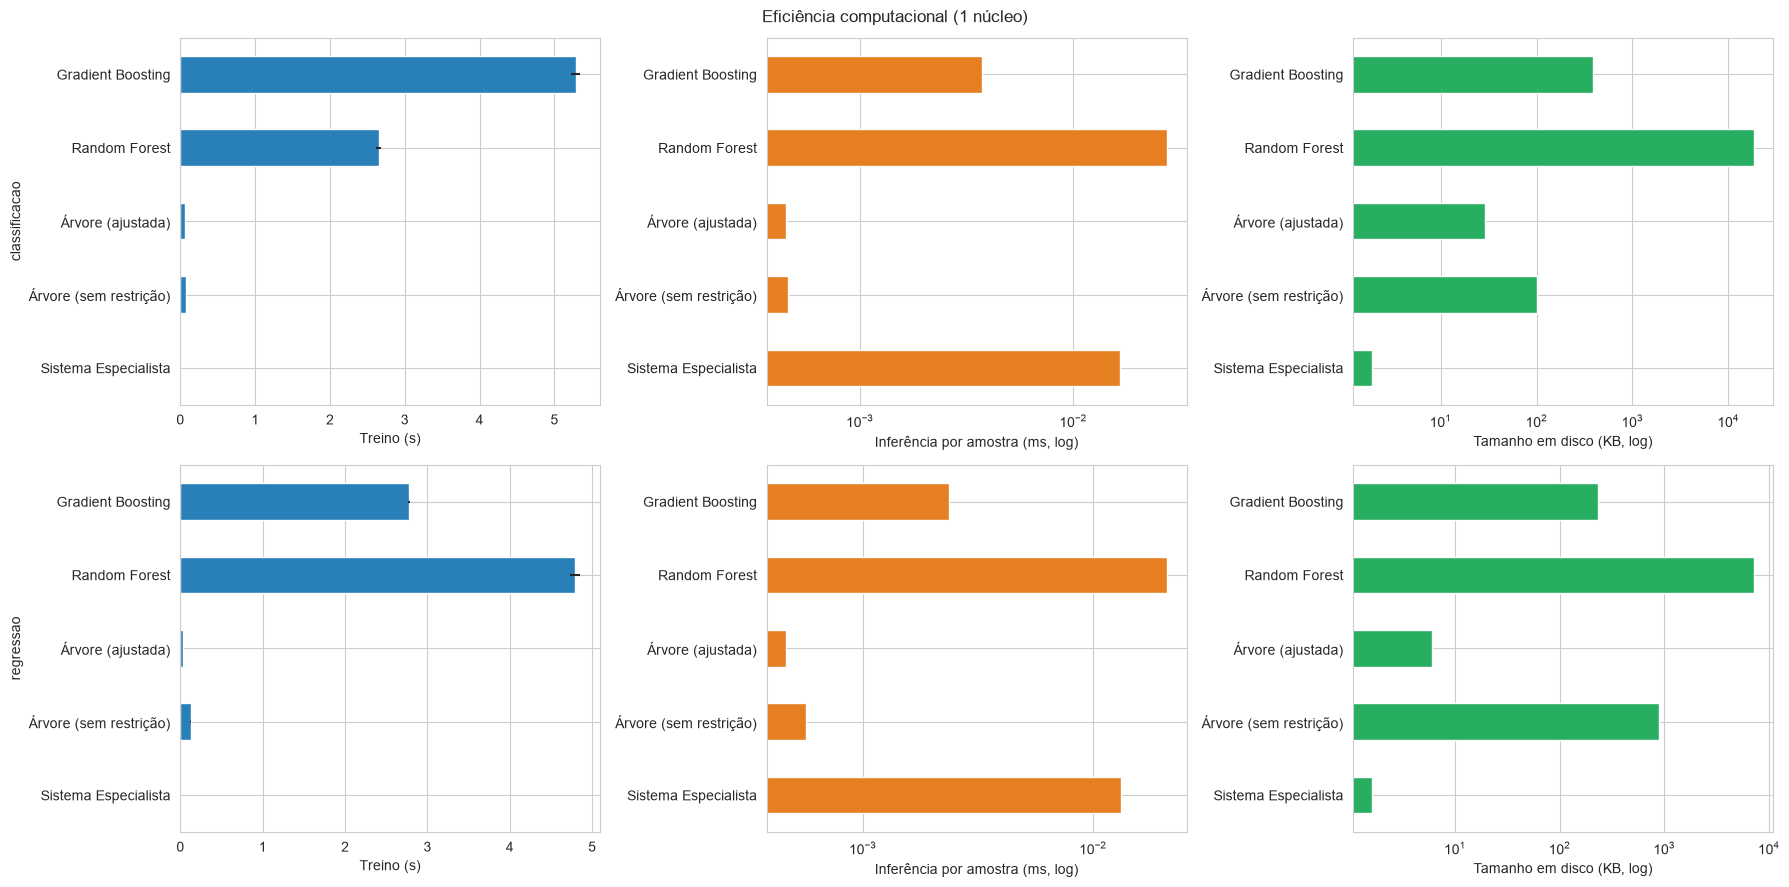

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for i, (p, df) in enumerate(efic.items()):
    df["treino_tempo_medio_s"].plot.barh(ax=axes[i, 0], xerr=df["treino_tempo_desvio_s"], color="#2980b9")
    axes[i, 0].set_xlabel("Treino (s)")
    df["inf_tempo_por_amostra_ms"].plot.barh(ax=axes[i, 1], color="#e67e22", logx=True)
    axes[i, 1].set_xlabel("Inferência por amostra (ms, log)")
    df["disco_kb"].plot.barh(ax=axes[i, 2], color="#27ae60", logx=True)
    axes[i, 2].set_xlabel("Tamanho em disco (KB, log)")
    axes[i, 0].set_ylabel(p)
    for ax in axes[i, 1:]:
        ax.set_ylabel("")
plt.suptitle("Eficiência computacional (1 núcleo)")
plt.tight_layout()
salvar_fig("eficiencia")
plt.show()

## 3. Tabela-resumo final

Desempenho no teste (notebook 06), gap e validação cruzada (07), eficiência (aqui) e
tempo de elaboração das regras (03), lado a lado.

In [7]:
crono = pd.read_csv(TABLES / "es_cronometragem_resumo.csv").set_index("problema")
resumos = []
for p, met_cols in [("classificacao", ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]),
                    ("regressao", ["MAE", "RMSE", "MAPE (%)", "R2", "MedAE"])]:
    met = pd.read_csv(TABLES / f"metricas_{p}.csv").query("conjunto == 'teste'").set_index("modelo")[met_cols]
    gen = pd.read_csv(TABLES / f"generalizacao_{p}.csv", index_col=0)[["gap", "cv_media", "cv_desvio", "diagnostico"]]
    ef = efic[p][["treino_tempo_medio_s", "inf_tempo_por_amostra_ms", "inf_vazao_amostras_s",
                  "treino_pico_memoria_kb", "inf_pico_memoria_kb", "disco_kb",
                  "treino_energia_kwh", "treino_co2_g", "inf_energia_kwh", "inf_co2_g"]]
    r = met.join(gen).join(ef)
    r["elaboracao_regras_min"] = np.nan
    if p in crono.index:
        r.loc["Sistema Especialista", "elaboracao_regras_min"] = crono.loc[p, "tempo_total_min"]
    r.insert(0, "problema", p)
    resumos.append(r)
resumo = pd.concat(resumos)
salvar_tabela(resumo, "resumo_final")
resumo

,problema,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,gap,cv_media,cv_desvio,...,treino_energia_kwh,treino_co2_g,inf_energia_kwh,inf_co2_g,elaboracao_regras_min,MAE,RMSE,MAPE (%),R2,MedAE
modelo,,,,,,,,,,,,,,,,,,,,,
Sistema Especialista,classificacao,0.833889,0.716549,0.746789,0.731357,0.897615,0.815656,0.017318,0.748762,0.017447,...,NaN,NaN,5.388035e-07,2.467720e-05,0.52,NaN,NaN,NaN,NaN,NaN
Árvore (sem restrição),classificacao,0.827778,0.730845,0.682569,0.705882,0.786703,0.594963,0.294118,0.698570,0.014955,...,1.444835e-06,0.000066,1.495578e-08,6.849746e-07,NaN,NaN,NaN,NaN,NaN,NaN
Árvore (ajustada),classificacao,0.856667,0.780822,0.732110,0.755682,0.884820,0.793061,0.068512,0.763598,0.023122,...,1.051396e-06,0.000048,1.460688e-08,6.689953e-07,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,classificacao,0.875556,0.800000,0.785321,0.792593,0.939379,0.884344,0.148426,0.804356,0.016319,...,4.785426e-05,0.002192,8.980006e-07,4.112843e-05,NaN,NaN,NaN,NaN,NaN,NaN
Gradient Boosting,classificacao,0.889444,0.854508,0.765138,0.807357,0.945052,0.900613,0.097427,0.819144,0.018344,...,9.543202e-05,0.004371,1.210176e-07,5.542606e-06,NaN,NaN,NaN,NaN,NaN,NaN
Sistema Especialista,regressao,NaN,NaN,NaN,NaN,NaN,NaN,-0.249337,12.329021,0.263808,...,NaN,NaN,4.314655e-07,1.976112e-05,0.45,9.936833,12.580615,6.192313,0.655368,8.400000
Árvore (sem restrição),regressao,NaN,NaN,NaN,NaN,NaN,NaN,-16.752147,17.115975,0.350719,...,2.261572e-06,0.000104,1.830159e-08,8.382129e-07,NaN,13.243333,16.752147,8.258606,0.388927,11.000000
Árvore (ajustada),regressao,NaN,NaN,NaN,NaN,NaN,NaN,-0.475074,12.084905,0.231475,...,5.450947e-07,0.000025,1.503306e-08,6.885139e-07,NaN,9.777663,12.297439,6.133796,0.670708,8.147738
Random Forest,regressao,NaN,NaN,NaN,NaN,NaN,NaN,-1.622111,11.952246,0.188922,...,8.648165e-05,0.003961,6.841810e-07,3.133549e-05,NaN,9.666834,12.128277,6.065036,0.679705,8.184076


In [8]:
with pd.option_context("display.float_format", "{:.4g}".format):
    for p in ("classificacao", "regressao"):
        print(f"\n===== {p} =====")
        print(resumo.query("problema == @p").drop(columns="problema").T.to_string())


===== classificacao =====
modelo                   Sistema Especialista Árvore (sem restrição) Árvore (ajustada) Random Forest Gradient Boosting
Accuracy                               0.8339                 0.8278            0.8567        0.8756            0.8894
Precision                              0.7165                 0.7308            0.7808           0.8            0.8545
Recall                                 0.7468                 0.6826            0.7321        0.7853            0.7651
F1                                     0.7314                 0.7059            0.7557        0.7926            0.8074
ROC-AUC                                0.8976                 0.7867            0.8848        0.9394            0.9451
PR-AUC                                 0.8157                  0.595            0.7931        0.8843            0.9006
gap                                   0.01732                 0.2941           0.06851        0.1484           0.09743
cv_media             